# Avaliação do checkpoint EfficientNet-B4 (TCC2) — somente inferência

Carrega o checkpoint já treinado e produz todos os números, tabelas e figuras do artigo a partir de uma única execução reprodutível.

**Ordem de execução:** Setup → Parte A (auditoria, só CPU) → Parte B (inferência, GPU) → Parte C (métricas) → Parte D (figuras) → Parte E (erros) → Parte F (registro da execução).
As predições ficam salvas em `preds_test.csv`; se o Colab desconectar, as Partes C–F podem ser refeitas sem GPU.


## Setup

In [ ]:
import os, json, hashlib, platform, random, sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass  # execução fora do Colab

SEED = 42
random.seed(SEED); np.random.seed(SEED)

BASE       = '/content/drive/MyDrive/TCC1/colab_data/isic'
TRAIN_DIR  = f'{BASE}/train'
TEST_DIR   = f'{BASE}/test'
CSV_PATH   = f'{BASE}/metadata.csv'
MODEL_PATH = f'{BASE}/results/melhor_modelo_efficientnetb4.h5'
OUT_DIR    = f'{BASE}/results_eval'
os.makedirs(OUT_DIR, exist_ok=True)

IMG_SIZE = 380
BATCH    = 32
CLASS_NAMES = ['Benign', 'Indeterminate', 'Malignant']
CLASS_MAP   = {n: i for i, n in enumerate(CLASS_NAMES)}
MALIGN = 2

# ---- Parâmetros da avaliação ----
N_BOOT = 2000                      # reamostragens do bootstrap (por paciente)
SENS_TARGETS = [0.70, 0.80, 0.90]  # metas de sensibilidade varridas na escolha de limiar
SENS_TARGET_PRIMARY = 0.80         # ponto de operação principal (defina e justifique ANTES de ver os resultados)
RECOMPUTE_PREDS = False            # True força refazer a inferência
SHOW_IMAGES = True                 # grade de imagens de erros (Parte E)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Parte A — Auditoria da base (CPU)

Responde: contagens por classe e partição, composição da classe "Malignant", arquivos sem metadado, duplicatas e **sobreposição de pacientes/lesões entre treino e teste**.

In [ ]:
df = pd.read_csv(CSV_PATH)
df['fname'] = df['isic_id'] + '.jpg'

files_train = set(os.listdir(TRAIN_DIR))
files_test  = set(os.listdir(TEST_DIR))
meta_files  = set(df['fname'])

df['particao'] = np.select(
    [df['fname'].isin(files_train), df['fname'].isin(files_test)],
    ['treino', 'teste'], default='fora')

audit = {
    'n_metadata': int(len(df)),
    'isic_id_duplicados': int(df['isic_id'].duplicated().sum()),
    'n_arquivos_train': len(files_train),
    'n_arquivos_test': len(files_test),
    'arquivos_em_train_e_test': len(files_train & files_test),
    'train_sem_metadata': len(files_train - meta_files),
    'test_sem_metadata': len(files_test - meta_files),
    'metadata_sem_imagem_em_train_ou_test': len(meta_files - files_train - files_test),
    'rotulo_diagnosis_1_nulo': int(df['diagnosis_1'].isna().sum()),
    'patient_id_nulo': int(df['patient_id'].isna().sum()),
    'n_pacientes_base': int(df['patient_id'].nunique()),
    'n_lesion_id_unicos_base': int(df['lesion_id'].nunique()),
    'valores_diagnosis_1': df['diagnosis_1'].value_counts(dropna=False).to_dict(),
    'licencas': df['copyright_license'].value_counts().to_dict(),
}

df_train = df[df['particao'] == 'treino'].copy().reset_index(drop=True)
df_test  = df[df['particao'] == 'teste'].copy().reset_index(drop=True)
for d in (df_train, df_test):
    d['label_int'] = d['diagnosis_1'].map(CLASS_MAP)
    assert d['label_int'].notna().all(), 'rótulo fora do mapeamento'
    d['label_int'] = d['label_int'].astype(int)

# ---- Tabela de classes (não há conjunto de validação separado neste experimento) ----
tab = pd.DataFrame({
    'Base original': df['diagnosis_1'].value_counts(),
    'Treino (antes do oversampling)': df_train['diagnosis_1'].value_counts(),
    'Teste': df_test['diagnosis_1'].value_counts(),
}).reindex(CLASS_NAMES).fillna(0).astype(int)
tab.loc['Total'] = tab.sum()

# ---- O que é "Malignant" nesta base? (diagnosis_3) ----
mal = df[df['diagnosis_1'] == 'Malignant']
comp_mal = pd.crosstab(mal['diagnosis_3'].fillna('(vazio)'), mal['particao'])
ind = df[df['diagnosis_1'] == 'Indeterminate']
comp_ind = pd.crosstab(ind['diagnosis_3'].fillna('(vazio)'), ind['particao'])

# ---- Vazamento por paciente / lesão ----
pat_tr, pat_te = set(df_train['patient_id']), set(df_test['patient_id'])
df_test['paciente_no_treino'] = df_test['patient_id'].isin(pat_tr)
df_test['lesao_no_treino'] = df_test['lesion_id'].isin(set(df_train['lesion_id'].dropna()))
audit.update({
    'pacientes_treino': len(pat_tr),
    'pacientes_teste': len(pat_te),
    'pacientes_em_ambos': len(pat_tr & pat_te),
    'imagens_teste_de_pacientes_vistos_no_treino': int(df_test['paciente_no_treino'].sum()),
    'imagens_teste_de_lesoes_vistas_no_treino': int(df_test['lesao_no_treino'].sum()),
})
vazamento = (df_test.groupby('diagnosis_1')['paciente_no_treino']
             .agg(['sum', 'count']).rename(columns={'sum': 'imgs_de_pacientes_vistos', 'count': 'imgs_teste'})
             .reindex(CLASS_NAMES).fillna(0).astype(int))
img_por_pac = pd.DataFrame({
    'treino': df_train.groupby('patient_id').size().describe(),
    'teste': df_test.groupby('patient_id').size().describe(),
})

print('=== AUDITORIA ==='); print(json.dumps(audit, indent=2, ensure_ascii=False, default=int))
print('\n=== Contagem por classe e partição ==='); print(tab.to_string())
print('\n=== Composição de Malignant (diagnosis_3) ==='); print(comp_mal.to_string())
print('\n=== Composição de Indeterminate (diagnosis_3) ==='); print(comp_ind.to_string())
print('\n=== Imagens de teste cujo paciente aparece no treino ==='); print(vazamento.to_string())
print('\n=== Imagens por paciente ==='); print(img_por_pac.round(1).to_string())
if audit['pacientes_em_ambos'] > 0:
    print('\nATENÇÃO: há pacientes em treino e teste. Possível vazamento: relate na seção de limitações '
          'e use o subconjunto de pacientes inéditos (Parte C).')

# ---- Salvar ----
tab.to_csv(f'{OUT_DIR}/tabela_classes.csv', encoding='utf-8-sig')
comp_mal.to_csv(f'{OUT_DIR}/composicao_malignas.csv', encoding='utf-8-sig')
vazamento.to_csv(f'{OUT_DIR}/vazamento_paciente.csv', encoding='utf-8-sig')
df[['isic_id', 'particao', 'diagnosis_1', 'diagnosis_3', 'patient_id', 'lesion_id']].to_csv(
    f'{OUT_DIR}/particoes_originais.csv', index=False)
with open(f'{OUT_DIR}/auditoria.json', 'w', encoding='utf-8') as f:
    json.dump(audit, f, indent=2, ensure_ascii=False, default=int)

=== AUDITORIA ===
{
  "n_metadata": 10982,
  "isic_id_duplicados": 0,
  "n_arquivos_train": 8713,
  "n_arquivos_test": 2269,
  "arquivos_em_train_e_test": 0,
  "train_sem_metadata": 0,
  "test_sem_metadata": 0,
  "metadata_sem_imagem_em_train_ou_test": 0,
  "rotulo_diagnosis_1_nulo": 0,
  "patient_id_nulo": 0,
  "n_pacientes_base": 690,
  "n_lesion_id_unicos_base": 10887,
  "valores_diagnosis_1": {
    "Benign": 10674,
    "Malignant": 262,
    "Indeterminate": 46
  },
  "licencas": {
    "CC-BY": 7175,
    "CC-BY-NC": 3807
  },
  "pacientes_treino": 690,
  "pacientes_teste": 585,
  "pacientes_em_ambos": 585,
  "imagens_teste_de_pacientes_vistos_no_treino": 2269,
  "imagens_teste_de_lesoes_vistas_no_treino": 26
}

=== Contagem por classe e partição ===
               Base original  Treino (antes do oversampling)  Teste
diagnosis_1                                                        
Benign                 10674                            8471   2203
Indeterminate             46     

## Parte B — Inferência determinística (GPU)

- Pré-processamento idêntico ao do treino, sem aleatoriedade: `Resize(380×380, INTER_LINEAR)` → `(x/255 − média)/desvio` do ImageNet.
- 4 visões por imagem (original, flip horizontal, flip vertical, ambos). `tta` = média das 4 probabilidades.
- Salva `preds_test.csv` (probabilidades por visão e do TTA). Se o arquivo existir, a inferência é pulada.

In [ ]:
import tensorflow as tf
import cv2
from tqdm.auto import tqdm

PRED_CSV = f'{OUT_DIR}/preds_test.csv'
MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
STD  = np.array([0.229, 0.224, 0.225], dtype=np.float32)

# Reduzindo o batch para evitar erro de falta de memória (OOM) na GPU
EVAL_BATCH = 8

def _resize_norm(img):
    img = cv2.resize(np.asarray(img, dtype=np.uint8), (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_LINEAR)
    return ((img.astype(np.float32) / 255.0 - MEAN) / STD).astype(np.float32)

def make_eval_dataset(paths):
    def _map(p):
        img = tf.io.decode_jpeg(tf.io.read_file(p), channels=3)
        x = tf.numpy_function(_resize_norm, [img], tf.float32)
        x.set_shape((IMG_SIZE, IMG_SIZE, 3))
        return x
    ds = tf.data.Dataset.from_tensor_slices(paths)
    ds = ds.map(_map, num_parallel_calls=tf.data.AUTOTUNE, deterministic=True)
    return ds.batch(EVAL_BATCH).prefetch(tf.data.AUTOTUNE)

# Tensores do batch: (B, H, W, C). axis=2 -> largura (flip horizontal); axis=1 -> altura (flip vertical)
VIEWS = {
    'orig':   lambda x: x,
    'flipH':  lambda x: tf.reverse(x, axis=[2]),
    'flipV':  lambda x: tf.reverse(x, axis=[1]),
    'flipHV': lambda x: tf.reverse(x, axis=[1, 2]),
}

# Custom objects para corrigir a desserializaçao de modelos com BatchNormalization herdada do Keras antigo
class CleanBatchNormalization(tf.keras.layers.BatchNormalization):
    @classmethod
    def from_config(cls, config):
        # Remove argumentos incompativeis com Keras 3
        for key in ['renorm', 'renorm_clipping', 'renorm_momentum']:
            config.pop(key, None)
        return super().from_config(config)

if os.path.exists(PRED_CSV) and not RECOMPUTE_PREDS:
    print(f'Prediçoes ja existem em {PRED_CSV}; inferencia pulada (RECOMPUTE_PREDS=True para refazer).')
else:
    # Executa o carregamento e predição na CPU para evitar ResourceExhaustedError (OOM) na GPU
    with tf.device('/cpu:0'):
        model = tf.keras.models.load_model(
            MODEL_PATH,
            compile=False,
            custom_objects={'BatchNormalization': CleanBatchNormalization}
        )
        print('entrada:', model.input_shape, '| saida:', model.output_shape)
        print('Mulltimas camadas:', [type(l).__name__ for l in model.layers[-6:]])
        print('Dropout:', sum(type(l).__name__ == 'Dropout' for l in model.layers),
              '| BatchNorm:', sum(type(l).__name__ == 'BatchNormalization' or type(l).__name__ == 'CleanBatchNormalization' for l in model.layers),
              '| camadas:', len(model.layers))
        assert tuple(model.input_shape[1:]) == (IMG_SIZE, IMG_SIZE, 3)
        assert model.output_shape[-1] == 3

        paths = [os.path.join(TEST_DIR, f) for f in df_test['fname']]
        assert all(os.path.exists(p) for p in paths), 'imagem de teste ausente'

        probs = {v: [] for v in VIEWS}
        for x in tqdm(make_eval_dataset(paths), total=int(np.ceil(len(paths) / EVAL_BATCH))):
            for v, f in VIEWS.items():
                probs[v].append(np.asarray(model(f(x), training=False), dtype=np.float64))
        probs = {v: np.concatenate(a) for v, a in probs.items()}
        probs['tta'] = np.mean([probs[v] for v in VIEWS], axis=0)

    for v, a in probs.items():
        assert a.shape == (len(df_test), 3) and np.isfinite(a).all(), f'saida invalida em {v}'
        assert np.allclose(a.sum(1), 1.0, atol=1e-2), f'softmax nao soma 1 em {v}'

    out = df_test[['isic_id', 'patient_id', 'lesion_id', 'diagnosis_1', 'label_int']].copy()
    for v, a in probs.items():
        for j, c in enumerate(CLASS_NAMES):
            out[f'p_{c}_{v}'] = a[:, j]
    out.to_csv(PRED_CSV, index=False)
    print('Salvo:', PRED_CSV, out.shape)

entrada: (None, 380, 380, 3) | saida: (None, 3)
Mulltimas camadas: ['Conv2D', 'CleanBatchNormalization', 'Activation', 'GlobalAveragePooling2D', 'Dropout', 'Dense']
Dropout: 26 | BatchNorm: 96 | camadas: 478


  0%|          | 0/284 [00:00<?, ?it/s]

Salvo: /content/drive/MyDrive/TCC1/colab_data/isic/results_eval/preds_test.csv (2269, 20)


## Parte C — Métricas da classe maligna (one-vs-rest)

**Definições (reportar na Seção 4.5):**
- Positivo = classe *Malignant*; negativo = *Benign* + *Indeterminate*.
- Regra `argmax`: positivo se a classe de maior probabilidade é *Malignant*.
- Regra `limiar t`: positivo se `p(Malignant) ≥ t`. No 3 classes, os não-positivos recebem a maior entre *Benign*/*Indeterminate*.
- **Escolha de limiar (cross-fitting):** o teste é dividido em 2 metades estratificadas e **separadas por paciente** (`StratifiedGroupKFold`, seed fixa). Em cada metade, escolhe-se o limiar que **maximiza a precisão entre os limiares com sensibilidade ≥ meta** (empate: menor limiar); ele é aplicado à outra metade. As predições das duas metades são reunidas.
- **IC 95%:** bootstrap percentil por **paciente** (reamostra pacientes inteiros). Não inclui a variabilidade da escolha do limiar nem a do treinamento.
- **Análise exploratória:** o teste já foi usado para selecionar o checkpoint; não há validação independente.

In [ ]:
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_recall_curve,
                             roc_curve, confusion_matrix, classification_report)
from sklearn.model_selection import StratifiedGroupKFold

preds = pd.read_csv(f'{OUT_DIR}/preds_test.csv')
extra_cols = ['isic_id', 'fname', 'paciente_no_treino', 'lesao_no_treino', 'anatom_site_1', 'sex',
              'age_approx', 'diagnosis_3', 'diagnosis_confirm_type', 'dermoscopic_type']
ev = preds.merge(df_test[extra_cols], on='isic_id', how='left', validate='one_to_one')
assert len(ev) == len(df_test)

y3 = ev['label_int'].values
y_bin = (y3 == MALIGN).astype(int)
groups = ev['patient_id'].values
S = {v: ev[[f'p_{c}_{v}' for c in CLASS_NAMES]].values for v in ('orig', 'tta')}
print(f'Teste: {len(ev)} imagens, {len(np.unique(groups))} pacientes, {y_bin.sum()} malignas '
      f'(prevalência {y_bin.mean():.4f})')

# ------------------------------------------------------------------ funções
def counts(y, pred):
    y = np.asarray(y).astype(bool); pred = np.asarray(pred).astype(bool)
    return (int((y & pred).sum()), int((~y & pred).sum()), int((y & ~pred).sum()), int((~y & ~pred).sum()))

def rates(tp, fp, fn, tn):
    return dict(
        sens=tp / (tp + fn) if tp + fn else np.nan,
        spec=tn / (tn + fp) if tn + fp else np.nan,
        ppv=tp / (tp + fp) if tp + fp else np.nan,
        npv=tn / (tn + fn) if tn + fn else np.nan,
        f1=2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) else np.nan)

def stat_point(y, pred, score=None):
    tp, fp, fn, tn = counts(y, pred)
    r = rates(tp, fp, fn, tn); r.update(tp=tp, fp=fp, fn=fn, tn=tn)
    if score is not None:
        r['roc_auc'] = roc_auc_score(y, score)
        r['pr_auc'] = average_precision_score(y, score)
    return r

def cluster_bootstrap(grp, y, pred, score=None, n_boot=N_BOOT, seed=SEED):
    rng = np.random.default_rng(seed)
    uniq, inv = np.unique(grp, return_inverse=True)
    members = [np.where(inv == g)[0] for g in range(len(uniq))]
    boot = []
    for _ in range(n_boot):
        idx = np.concatenate([members[g] for g in rng.integers(0, len(uniq), len(uniq))])
        if y[idx].sum() == 0 or y[idx].sum() == len(idx):
            continue
        boot.append(stat_point(y[idx], pred[idx], None if score is None else score[idx]))
    return pd.DataFrame(boot)

def summarize(name, y, pred, score, grp, extra=None):
    pt = stat_point(y, pred, score)
    bs = cluster_bootstrap(grp, y, pred, score)
    row = {'config': name, 'n_pos': int(y.sum()), 'n_neg': int(len(y) - y.sum())}
    for k in ('sens', 'ppv', 'spec', 'f1', 'roc_auc', 'pr_auc'):
        if k in pt:
            lo, hi = np.nanpercentile(bs[k], [2.5, 97.5])
            row[k] = pt[k]; row[k + '_ic95'] = f'[{lo:.3f}; {hi:.3f}]'
    row.update(tp=pt['tp'], fp=pt['fp'], fn=pt['fn'], tn=pt['tn'], npv=pt['npv'], n_boot_validos=len(bs))
    if extra: row.update(extra)
    return row

def pick_threshold(y, s, target):
    # maximiza a precisão entre os limiares com sensibilidade >= meta (empate: menor limiar)
    if y.sum() == 0:
        raise ValueError('metade sem casos malignos')
    prec, rec, thr = precision_recall_curve(y, s)
    prec, rec = prec[:-1], rec[:-1]
    ok = np.where(rec >= target)[0]
    return float(thr[ok[np.argmax(prec[ok])]])

def crossfit(y, s, grp, target, seed=SEED):
    skf = StratifiedGroupKFold(n_splits=2, shuffle=True, random_state=seed)
    pred = np.zeros(len(y), bool); info = []
    for k, (sel, ev_) in enumerate(skf.split(np.zeros(len(y)), y, grp)):
        t = pick_threshold(y[sel], s[sel], target)
        pred[ev_] = s[ev_] >= t
        info.append(dict(metade_avaliada=k, limiar=t, n_selecao=len(sel), pos_selecao=int(y[sel].sum()),
                         n_avaliacao=len(ev_), pos_avaliacao=int(y[ev_].sum())))
    return pred, pd.DataFrame(info)

def pred3(P, flag):
    out = P[:, :2].argmax(1)   # entre Benign e Indeterminate
    out[flag] = MALIGN
    return out

Teste: 2269 imagens, 585 pacientes, 62 malignas (prevalência 0.0273)


In [ ]:
# ------------------------------------------------------------------ resultados principais
rows, cf_pred, cf_info = [], {}, {}
for v in ('orig', 'tta'):
    s = S[v][:, MALIGN]
    pred_arg = S[v].argmax(1) == MALIGN
    rows.append(summarize(f'argmax | {v}', y_bin, pred_arg, s, groups))
    for tgt in SENS_TARGETS:
        pred_cf, info = crossfit(y_bin, s, groups, tgt)
        cf_pred[(v, tgt)], cf_info[(v, tgt)] = pred_cf, info
        thr_txt = ' / '.join(f'{t:.3f}' for t in info['limiar'])
        rows.append(summarize(f'limiar cross-fit (sens>={tgt:.2f}) | {v}', y_bin, pred_cf, s, groups,
                              extra={'limiares_por_metade': thr_txt}))

res = pd.DataFrame(rows)
cols = ['config', 'n_pos', 'n_neg', 'sens', 'sens_ic95', 'ppv', 'ppv_ic95', 'spec', 'spec_ic95', 'f1', 'f1_ic95',
        'roc_auc', 'roc_auc_ic95', 'pr_auc', 'pr_auc_ic95', 'tp', 'fp', 'fn', 'tn', 'npv', 'limiares_por_metade']
res = res[[c for c in cols if c in res.columns]]
res.to_csv(f'{OUT_DIR}/resultados_maligna.csv', index=False, encoding='utf-8-sig')
for k, info in cf_info.items():
    info.to_csv(f'{OUT_DIR}/limiares_crossfit_{k[0]}_sens{int(k[1]*100)}.csv', index=False)
print(f'Prevalência de malignas no teste: {y_bin.mean():.4f} (precisão de um classificador aleatório ≈ prevalência)\n')
print(res.round(4).to_string(index=False))

Prevalência de malignas no teste: 0.0273 (precisão de um classificador aleatório ≈ prevalência)

                              config  n_pos  n_neg   sens      sens_ic95    ppv       ppv_ic95   spec      spec_ic95     f1        f1_ic95  roc_auc   roc_auc_ic95  pr_auc    pr_auc_ic95  tp   fp  fn   tn    npv limiares_por_metade
                       argmax | orig     62   2207 0.5645 [0.433; 0.697] 0.0962 [0.066; 0.131] 0.8509 [0.827; 0.872] 0.1643 [0.115; 0.216]   0.7879 [0.717; 0.849]  0.1215 [0.078; 0.195]  35  329  27 1878 0.9858                 NaN
limiar cross-fit (sens>=0.70) | orig     62   2207 0.6129 [0.480; 0.741] 0.0745 [0.051; 0.099] 0.7861 [0.755; 0.815] 0.1329 [0.093; 0.173]   0.7879 [0.717; 0.849]  0.1215 [0.078; 0.195]  38  472  24 1735 0.9864       0.481 / 0.411
limiar cross-fit (sens>=0.80) | orig     62   2207 0.7903 [0.676; 0.898] 0.0623 [0.045; 0.082] 0.6661 [0.627; 0.703] 0.1156 [0.084; 0.149]   0.7879 [0.717; 0.849]  0.1215 [0.078; 0.195]  49  737  13 1470 0.9912

In [ ]:
# ------------------------------------------------------------------ 3 classes (descritivo)
for v in ('orig', 'tta'):
    p3 = S[v].argmax(1)
    rep = classification_report(y3, p3, labels=[0, 1, 2], target_names=CLASS_NAMES, zero_division=0, output_dict=True)
    pd.DataFrame(rep).T.to_csv(f'{OUT_DIR}/relatorio_3classes_{v}.csv', encoding='utf-8-sig')
    print(f'--- 3 classes, argmax, {v} ---')
    print(classification_report(y3, p3, labels=[0, 1, 2], target_names=CLASS_NAMES, zero_division=0))
    print(confusion_matrix(y3, p3, labels=[0, 1, 2]), '\n')
print('Indeterminate tem apenas', int((y3 == 1).sum()),
      'amostras no teste: métricas descritivas, sem conclusão de generalização.')

--- 3 classes, argmax, orig ---
               precision    recall  f1-score   support

       Benign       0.99      0.82      0.89      2203
Indeterminate       0.00      0.00      0.00         4
    Malignant       0.10      0.56      0.16        62

     accuracy                           0.81      2269
    macro avg       0.36      0.46      0.35      2269
 weighted avg       0.96      0.81      0.87      2269

[[1797   80  326]
 [   1    0    3]
 [  22    5   35]] 

--- 3 classes, argmax, tta ---
               precision    recall  f1-score   support

       Benign       0.99      0.82      0.90      2203
Indeterminate       0.00      0.00      0.00         4
    Malignant       0.10      0.56      0.17        62

     accuracy                           0.82      2269
    macro avg       0.36      0.46      0.36      2269
 weighted avg       0.96      0.82      0.88      2269

[[1816   85  302]
 [   1    0    3]
 [  21    6   35]] 

Indeterminate tem apenas 4 amostras no teste: m

In [ ]:
# ------------------------------------------------------------------ pacientes vistos x inéditos (evidência de vazamento)
vistos = ev['paciente_no_treino'].values.astype(bool)
rows_sub = []
for nome, mask in (('pacientes INÉDITOS no treino', ~vistos), ('pacientes VISTOS no treino', vistos)):
    n_pos = int(y_bin[mask].sum())
    print(f'{nome}: {int(mask.sum())} imagens, {len(np.unique(groups[mask]))} pacientes, {n_pos} malignas')
    if n_pos < 2 or n_pos == mask.sum():
        print('   (casos malignos insuficientes: subconjunto não avaliado)'); continue
    if n_pos < 20:
        print('   AVISO: poucos casos malignos; ICs serão muito largos.')
    for v in ('orig', 'tta'):
        s = S[v][:, MALIGN]
        rows_sub.append(summarize(f'argmax | {v} | {nome}', y_bin[mask], (S[v].argmax(1) == MALIGN)[mask],
                                  s[mask], groups[mask]))
if rows_sub:
    sub = pd.DataFrame(rows_sub)
    sub = sub[[c for c in cols if c in sub.columns]]
    sub.to_csv(f'{OUT_DIR}/resultados_subconjuntos_paciente.csv', index=False, encoding='utf-8-sig')
    print(); print(sub.round(4).to_string(index=False))

pacientes INÉDITOS no treino: 0 imagens, 0 pacientes, 0 malignas
   (casos malignos insuficientes: subconjunto não avaliado)
pacientes VISTOS no treino: 2269 imagens, 585 pacientes, 62 malignas

                                    config  n_pos  n_neg   sens      sens_ic95    ppv       ppv_ic95   spec      spec_ic95     f1        f1_ic95  roc_auc   roc_auc_ic95  pr_auc    pr_auc_ic95  tp  fp  fn   tn    npv
argmax | orig | pacientes VISTOS no treino     62   2207 0.5645 [0.433; 0.697] 0.0962 [0.066; 0.131] 0.8509 [0.827; 0.872] 0.1643 [0.115; 0.216]   0.7879 [0.717; 0.849]  0.1215 [0.078; 0.195]  35 329  27 1878 0.9858
 argmax | tta | pacientes VISTOS no treino     62   2207 0.5645 [0.426; 0.698] 0.1029 [0.070; 0.140] 0.8618 [0.839; 0.882] 0.1741 [0.121; 0.230]   0.7924 [0.720; 0.854]  0.1353 [0.086; 0.226]  35 305  27 1902 0.9860


In [ ]:
# ------------------------------------------------------------------ EXPLORATÓRIO: deslocamento de prior causado pelo oversampling
# No treino as 3 classes ficaram ~1/3 cada (oversampling); no mundo real a prevalência é bem menor.
# Correção de Bayes aproximada: p_ajustada ∝ p * (prior_original / prior_treino_balanceado).
prior_orig = df_train['label_int'].value_counts(normalize=True).reindex(range(3)).values
def prior_adjust(P):
    a = P * (prior_orig / np.full(3, 1 / 3)); return a / a.sum(1, keepdims=True)

rows_p = []
for v in ('orig', 'tta'):
    Pa = prior_adjust(S[v])
    print(f'[{v}] média de p(Malignant): bruta={S[v][:, MALIGN].mean():.3f} | ajustada={Pa[:, MALIGN].mean():.3f} '
          f'| prevalência real no teste={y_bin.mean():.3f}')
    rows_p.append(summarize(f'argmax com prior ajustada | {v}', y_bin, Pa.argmax(1) == MALIGN, Pa[:, MALIGN], groups))
resp = pd.DataFrame(rows_p)[[c for c in cols if c in pd.DataFrame(rows_p).columns]]
resp.to_csv(f'{OUT_DIR}/resultados_prior_ajustado.csv', index=False, encoding='utf-8-sig')
print(resp.round(4).to_string(index=False))
print('Aproximação exploratória: softmax não é probabilidade clínica calibrada; use apenas para discutir o viés do oversampling.')

[orig] média de p(Malignant): bruta=0.275 | ajustada=0.014 | prevalência real no teste=0.027


/usr/local/lib/python3.13/dist-packages/numpy/lib/_nanfunctions_impl.py:1396: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(


[tta] média de p(Malignant): bruta=0.270 | ajustada=0.013 | prevalência real no teste=0.027
                          config  n_pos  n_neg  sens      sens_ic95  ppv   ppv_ic95  spec      spec_ic95  f1        f1_ic95  roc_auc   roc_auc_ic95  pr_auc    pr_auc_ic95  tp  fp  fn   tn    npv
argmax com prior ajustada | orig     62   2207   0.0 [0.000; 0.000]  NaN [nan; nan]   1.0 [1.000; 1.000] 0.0 [0.000; 0.000]   0.8098 [0.745; 0.864]  0.1287 [0.085; 0.199]   0   0  62 2207 0.9727
 argmax com prior ajustada | tta     62   2207   0.0 [0.000; 0.000]  NaN [nan; nan]   1.0 [1.000; 1.000] 0.0 [0.000; 0.000]   0.8120 [0.748; 0.865]  0.1401 [0.091; 0.226]   0   0  62 2207 0.9727
Aproximação exploratória: softmax não é probabilidade clínica calibrada; use apenas para discutir o viés do oversampling.


/usr/local/lib/python3.13/dist-packages/numpy/lib/_nanfunctions_impl.py:1396: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(


## Parte D — Figuras (300 dpi, paleta Okabe-Ito)

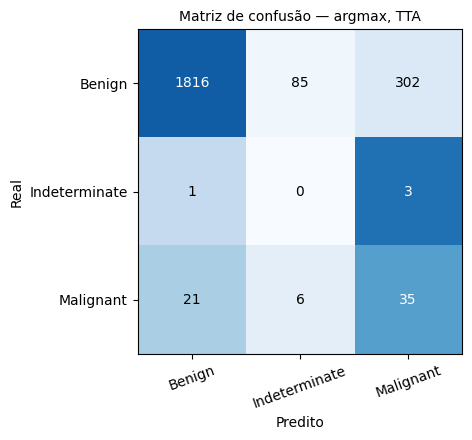

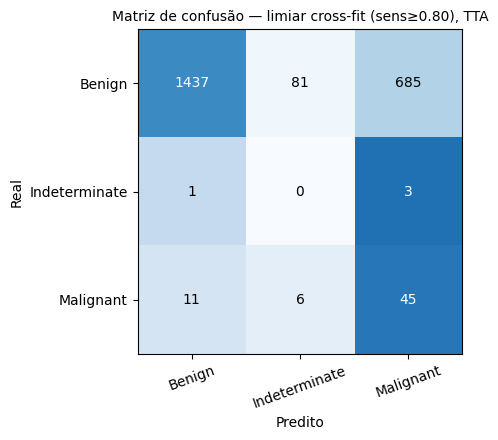

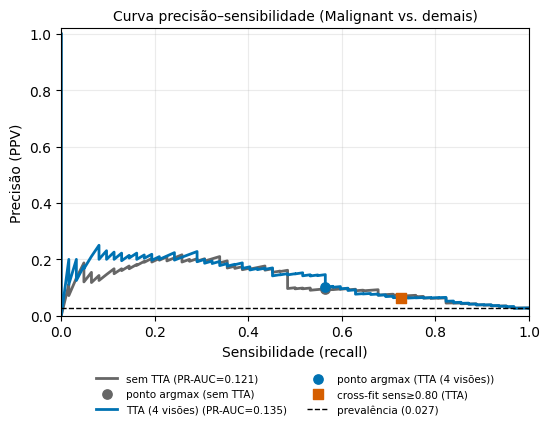

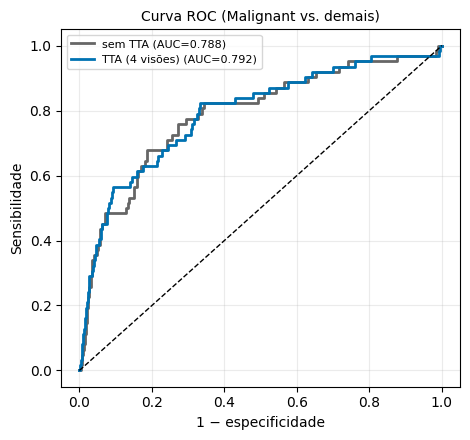

In [ ]:
BLUE, ORANGE, VERM, GRAY = '#0072B2', '#E69F00', '#D55E00', '#666666'

def plot_cm(cm, title, fname):
    cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)   # cor = fração da linha; texto = contagem
    fig, ax = plt.subplots(figsize=(5.4, 4.5))
    ax.imshow(cmn, cmap='Blues', vmin=0, vmax=1)
    ax.set_xticks(range(3)); ax.set_xticklabels(CLASS_NAMES, rotation=20)
    ax.set_yticks(range(3)); ax.set_yticklabels(CLASS_NAMES)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, str(cm[i, j]), ha='center', va='center', color='white' if cmn[i, j] > 0.5 else 'black')
    ax.set_xlabel('Predito'); ax.set_ylabel('Real'); ax.set_title(title, fontsize=10)
    fig.tight_layout(); fig.savefig(f'{OUT_DIR}/{fname}', dpi=300); plt.show()

cm_arg = confusion_matrix(y3, S['tta'].argmax(1), labels=[0, 1, 2])
plot_cm(cm_arg, 'Matriz de confusão — argmax, TTA', 'fig_cm_argmax_tta.png')

flag = cf_pred[('tta', SENS_TARGET_PRIMARY)]
cm_cf = confusion_matrix(y3, pred3(S['tta'], flag), labels=[0, 1, 2])
plot_cm(cm_cf, f'Matriz de confusão — limiar cross-fit (sens≥{SENS_TARGET_PRIMARY:.2f}), TTA', 'fig_cm_crossfit_tta.png')

# curva precisão–sensibilidade
fig, ax = plt.subplots(figsize=(5.6, 4.5))
for v, col, lab in (('orig', GRAY, 'sem TTA'), ('tta', BLUE, 'TTA (4 visões)')):
    s = S[v][:, MALIGN]
    p_, r_, _ = precision_recall_curve(y_bin, s)
    ax.plot(r_, p_, color=col, lw=2, label=f'{lab} (PR-AUC={average_precision_score(y_bin, s):.3f})')
    pa = S[v].argmax(1) == MALIGN; tp, fp, fn, tn = counts(y_bin, pa); rr = rates(tp, fp, fn, tn)
    ax.scatter(rr['sens'], rr['ppv'], color=col, marker='o', s=45, zorder=3, label=f'ponto argmax ({lab})')
rr = rates(*counts(y_bin, flag))
ax.scatter(rr['sens'], rr['ppv'], color=VERM, marker='s', s=60, zorder=4, label=f'cross-fit sens≥{SENS_TARGET_PRIMARY:.2f} (TTA)')
ax.axhline(y_bin.mean(), color='black', ls='--', lw=1, label=f'prevalência ({y_bin.mean():.3f})')
ax.set_xlabel('Sensibilidade (recall)'); ax.set_ylabel('Precisão (PPV)'); ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
ax.set_title('Curva precisão–sensibilidade (Malignant vs. demais)', fontsize=10)
ax.legend(fontsize=7.5, loc='upper center', bbox_to_anchor=(0.5, -0.17), ncol=2, frameon=False); ax.grid(alpha=0.25)
fig.tight_layout(); fig.savefig(f'{OUT_DIR}/fig_pr_curve.png', dpi=300, bbox_inches='tight'); plt.show()

# curva ROC
fig, ax = plt.subplots(figsize=(4.8, 4.5))
for v, col, lab in (('orig', GRAY, 'sem TTA'), ('tta', BLUE, 'TTA (4 visões)')):
    s = S[v][:, MALIGN]; fpr, tpr, _ = roc_curve(y_bin, s)
    ax.plot(fpr, tpr, color=col, lw=2, label=f'{lab} (AUC={roc_auc_score(y_bin, s):.3f})')
ax.plot([0, 1], [0, 1], color='black', ls='--', lw=1)
ax.set_xlabel('1 − especificidade'); ax.set_ylabel('Sensibilidade'); ax.legend(fontsize=8); ax.grid(alpha=0.25)
ax.set_title('Curva ROC (Malignant vs. demais)', fontsize=10)
fig.tight_layout(); fig.savefig(f'{OUT_DIR}/fig_roc.png', dpi=300); plt.show()

## Parte E — Análise de erros (descritiva)

Ponto de operação analisado: limiar cross-fit na meta principal, com TTA. Os agrupamentos abaixo descrevem **onde** os erros ocorrem na base; não explicam causas clínicas (isso exigiria avaliação de especialista).

In [ ]:
ev['p_mal'] = S['tta'][:, MALIGN]
ev['y_bin'] = y_bin
ev['flag'] = flag
ev['erro'] = np.select([(ev['y_bin'] == 1) & ~ev['flag'], (ev['y_bin'] == 0) & ev['flag']], ['FN', 'FP'], default='')
ev['diagnosis_3'] = ev['diagnosis_3'].fillna('(vazio)')

def taxa(df_, col, positivo):
    # positivo=True -> sensibilidade por grupo (entre malignas); False -> taxa de FP por grupo (entre não malignas)
    sub = df_[df_['y_bin'] == (1 if positivo else 0)]
    g = sub.groupby(col, dropna=False).agg(n=('flag', 'size'), sinalizadas=('flag', 'sum'))
    g['taxa'] = g['sinalizadas'] / g['n']
    return g.sort_values('n', ascending=False)

print('Sensibilidade por diagnosis_3 (entre malignas):'); print(taxa(ev, 'diagnosis_3', True).round(3).to_string())
for col in ('diagnosis_confirm_type', 'anatom_site_1', 'dermoscopic_type'):
    print(f'\nSensibilidade por {col}:'); print(taxa(ev, col, True).round(3).to_string())
print('\nTaxa de falso positivo por diagnosis_3 (entre não malignas):'); print(taxa(ev, 'diagnosis_3', False).round(3).head(12).to_string())
for col in ('diagnosis_confirm_type', 'anatom_site_1', 'dermoscopic_type'):
    print(f'\nTaxa de FP por {col}:'); print(taxa(ev, col, False).round(3).to_string())

errs = ev[ev['erro'] != ''][['isic_id', 'patient_id', 'erro', 'p_mal', 'diagnosis_1', 'diagnosis_3',
                              'diagnosis_confirm_type', 'anatom_site_1', 'sex', 'age_approx', 'dermoscopic_type']]
errs.sort_values(['erro', 'p_mal']).to_csv(f'{OUT_DIR}/erros_FP_FN.csv', index=False, encoding='utf-8-sig')
print('\nErros salvos:', errs['erro'].value_counts().to_dict())

Sensibilidade por diagnosis_3 (entre malignas):
                    n  sinalizadas   taxa
diagnosis_3                              
Melanoma, NOS      28           24  0.857
Melanoma in situ   20           11  0.550
Melanoma Invasive  14           10  0.714

Sensibilidade por diagnosis_confirm_type:
                         n  sinalizadas   taxa
diagnosis_confirm_type                        
histopathology          62           45  0.726

Sensibilidade por anatom_site_1:
                  n  sinalizadas   taxa
anatom_site_1                          
Trunk            29           25  0.862
Lower extremity  14            8  0.571
Head and neck     9            6  0.667
Upper extremity   8            5  0.625
NaN               2            1  0.500

Sensibilidade por dermoscopic_type:
                        n  sinalizadas   taxa
dermoscopic_type                             
NaN                    42           29  0.690
contact polarized      18           16  0.889
contact non-polarized  

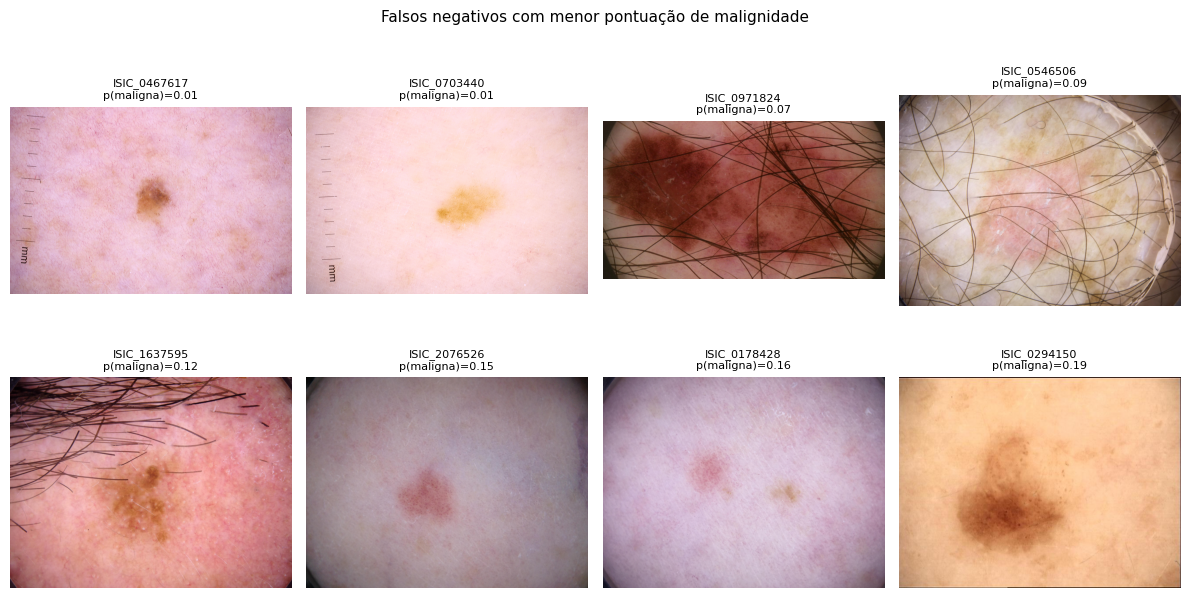

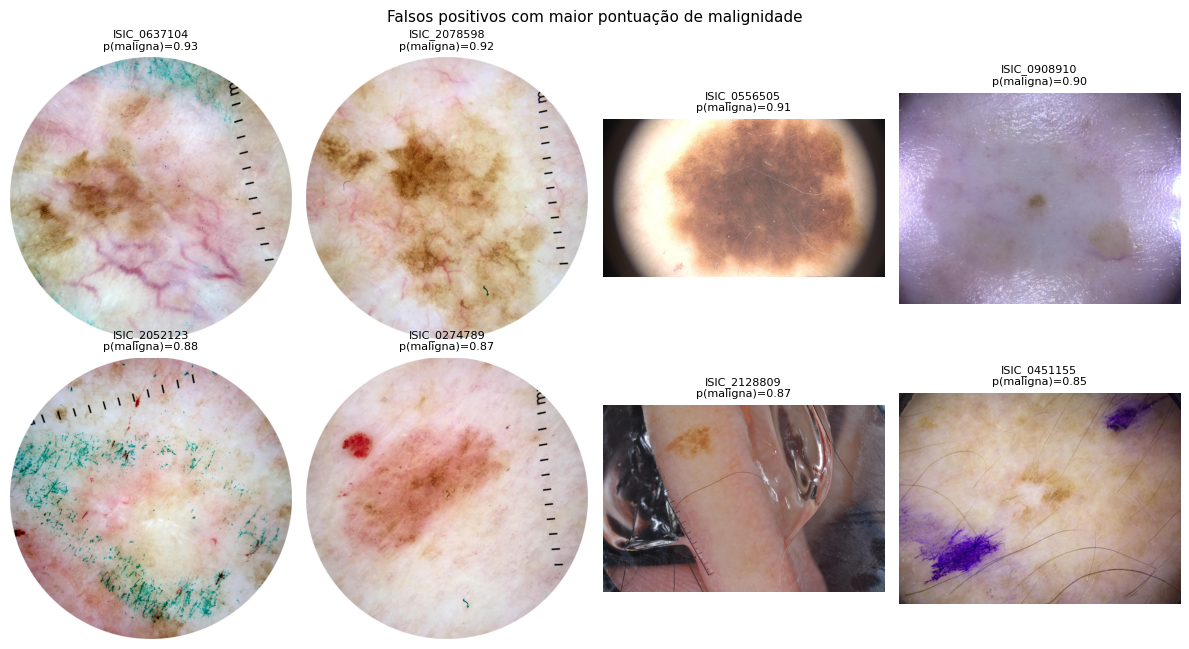

In [ ]:
def show_grid(rows_df, title, fname, n=8):
    fig, axes = plt.subplots(2, 4, figsize=(12, 6.6))
    for ax in axes.ravel(): ax.axis('off')
    for ax, (_, r) in zip(axes.ravel(), rows_df.head(n).iterrows()):
        ax.imshow(plt.imread(os.path.join(TEST_DIR, r['fname'])))
        ax.set_title(f"{r['isic_id']}\np(maligna)={r['p_mal']:.2f}", fontsize=8)
    fig.suptitle(title, fontsize=11); fig.tight_layout()
    fig.savefig(f'{OUT_DIR}/{fname}', dpi=200); plt.show()

if SHOW_IMAGES:
    fn_df = ev[ev['erro'] == 'FN'].sort_values('p_mal')                     # malignas com menor pontuação
    fp_df = ev[ev['erro'] == 'FP'].sort_values('p_mal', ascending=False)    # não malignas com maior pontuação
    if len(fn_df): show_grid(fn_df, 'Falsos negativos com menor pontuação de malignidade', 'fig_fn_exemplos.png')
    if len(fp_df): show_grid(fp_df, 'Falsos positivos com maior pontuação de malignidade', 'fig_fp_exemplos.png')

## Parte F — Registro da execução (reprodutibilidade)

In [ ]:
def sha256(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for b in iter(lambda: f.read(chunk), b''):
            h.update(b)
    return h.hexdigest()

info = {
    'data_execucao': time.strftime('%Y-%m-%d %H:%M:%S'),
    'seed': SEED, 'n_boot': N_BOOT, 'sens_targets': SENS_TARGETS, 'sens_target_primary': SENS_TARGET_PRIMARY,
    'img_size': IMG_SIZE, 'batch': BATCH,
    'preprocessamento': 'Resize INTER_LINEAR + (x/255 - mean)/std (ImageNet); sem augmentation aleatório',
    'tta': 'orig + flip horizontal + flip vertical + ambos; média das probabilidades',
    'python': platform.python_version(),
    'numpy': np.__version__, 'pandas': pd.__version__,
}
try:
    import sklearn, cv2 as _cv2
    info.update(sklearn=sklearn.__version__, opencv=_cv2.__version__)
    import tensorflow as _tf
    info.update(tensorflow=_tf.__version__, gpus=[g.name for g in _tf.config.list_physical_devices('GPU')])
except ImportError:
    pass
if os.path.exists(MODEL_PATH):
    info['checkpoint'] = {'arquivo': MODEL_PATH, 'bytes': os.path.getsize(MODEL_PATH),
                          'modificado_em': time.strftime('%Y-%m-%d %H:%M:%S', time.localtime(os.path.getmtime(MODEL_PATH))),
                          'sha256': sha256(MODEL_PATH)}
with open(f'{OUT_DIR}/run_info.json', 'w', encoding='utf-8') as f:
    json.dump(info, f, indent=2, ensure_ascii=False, default=str)
print(json.dumps(info, indent=2, ensure_ascii=False, default=str))
print('\nArquivos em', OUT_DIR, ':'); print('\n'.join(sorted(os.listdir(OUT_DIR))))

{
  "data_execucao": "2026-11-06 04:09:04",
  "seed": 42,
  "n_boot": 2000,
  "sens_targets": [
    0.7,
    0.8,
    0.9
  ],
  "sens_target_primary": 0.8,
  "img_size": 380,
  "batch": 32,
  "preprocessamento": "Resize INTER_LINEAR + (x/255 - mean)/std (ImageNet); sem augmentation aleatório",
  "tta": "orig + flip horizontal + flip vertical + ambos; média das probabilidades",
  "python": "3.13.16",
  "numpy": "2.4.6",
  "pandas": "2.2.3",
  "sklearn": "1.6.1",
  "opencv": "4.14.0",
  "tensorflow": "2.21.0",
  "gpus": [
    "/physical_device:GPU:0"
  ],
  "checkpoint": {
    "arquivo": "/content/drive/MyDrive/TCC1/colab_data/isic/results/melhor_modelo_efficientnetb4.h5",
    "bytes": 182375384,
    "modificado_em": "2026-06-22 19:53:42",
    "sha256": "91286cf78f104ddeecd6d3f069d764e5c06389ee683bf8599d34af035da88fda"
  }
}

Arquivos em /content/drive/MyDrive/TCC1/colab_data/isic/results_eval :
auditoria.json
composicao_malignas.csv
erros_FP_FN.csv
fig_cm_argmax_tta.png
fig_cm_crossfit